In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval
from scipy.ndimage import map_coordinates, gaussian_filter
from scipy.signal import fftconvolve
from IPython.display import Image, display
%matplotlib inline
plt.rcParams.update({"font.size": 10})

In [2]:
INPUT_FOLDER = Path(r"C:\Users\imans\Downloads\ComputationalImageProcessing\CP")
LAB_FILE = INPUT_FOLDER.parent / "Astro/Astro/Fits_Data/mosaic.fits"
R_4_3 = INPUT_FOLDER / "LH_Mosaic_opt_tile_4_3_r_mos32.fits"
R_4_4 = INPUT_FOLDER / "LH_Mosaic_opt_tile_4_4_r_mos32.fits"
I_4_3 = INPUT_FOLDER / "LH_Mosaic_opt_tile_4_3_i_mos32.fits"
I_4_4 = INPUT_FOLDER / "LH_Mosaic_opt_tile_4_4_i_mos32.fits"

FILES = {"lab": str(LAB_FILE),
         "original_band_tiles": [str(R_4_3), str(R_4_4)],
         "second_band_tiles": [str(I_4_3), str(I_4_4)]}
OUTPUT_FOLDER = INPUT_FOLDER / "sky_patch_notebook_output"
ZERO_IS_MISSING = True
for filename in [LAB_FILE, R_4_3, R_4_4, I_4_3, I_4_4]:
    if not filename.is_file():
        raise FileNotFoundError(filename)
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print("Outputs:", OUTPUT_FOLDER)

Outputs: C:\Users\imans\Downloads\ComputationalImageProcessing\CP\sky_patch_notebook_output


In [3]:
class FITSSection:
    """Read small scaled sections, including unsigned FITS with BZERO."""
    def __init__(self,hdu):
        self.hdu=hdu
        self.shape=(hdu.header['NAXIS2'],hdu.header['NAXIS1'])

    def __getitem__(self,item):
        if isinstance(item,tuple) and len(item)==2 and all(isinstance(k,slice) for k in item):
            ys,xs=item
            yr=range(*ys.indices(self.shape[0]));xr=range(*xs.indices(self.shape[1]))
            if yr.step>0 and xr.step>1:
                return np.asarray([self.hdu.section[y,xr.start:xr.stop][::xr.step] for y in yr])
        return self.hdu.section[item]


def open_image(filename):
    """Find a celestial 2-D image; data are read later through small sections."""
    hdus = fits.open(filename, memmap=False)
    try:
        for index, hdu in enumerate(hdus):
            if hdu.header.get('NAXIS') != 2:
                continue
            header = hdus[0].header.copy()
            header.extend(hdu.header, update=True)
            wcs = WCS(header).celestial
            if wcs.has_celestial:
                return hdus, index, header, wcs
        raise ValueError(f'No 2-D celestial image found: {filename}')
    except Exception:
        hdus.close()
        raise


def footprint_on_tile(lab_wcs, shape, tile_wcs):
    """Sample all four edges, including curvature from different projections."""
    ny, nx = shape
    t = np.linspace(0, 1, 150)
    x = np.r_[t*(nx-1), np.full_like(t,nx-1), (1-t)*(nx-1), np.zeros_like(t), 0]
    y = np.r_[np.zeros_like(t), t*(ny-1), np.full_like(t,ny-1), (1-t)*(ny-1), 0]
    sky = lab_wcs.pixel_to_world(x,y)
    return tile_wcs.world_to_pixel(sky)


def resample_to_lab(tile, tile_wcs, lab_wcs, shape):
    """Bilinear interpolation in small row blocks; retain only fully valid support.

    This is a geometry/visual check, NOT flux-conserving reprojection. In
    particular it must not be used as calibrated aperture photometry when
    detector pixel areas differ. Measure colours on the native images instead.
    """
    result = np.full(shape,np.nan,dtype=np.float32)
    for start in range(0,shape[0],128):
        stop=min(start+128,shape[0])
        yy,xx=np.mgrid[start:stop,0:shape[1]]
        sx,sy=tile_wcs.world_to_pixel(lab_wcs.pixel_to_world(xx,yy))
        # Round-trip WCS transforms can put an exact border infinitesimally out.
        tolerance=1e-5
        inside=np.isfinite(sx)&np.isfinite(sy)&(sx>=-tolerance)&(sy>=-tolerance)&(sx<=tile.shape[1]-1+tolerance)&(sy<=tile.shape[0]-1+tolerance)
        sx=np.clip(sx,0,tile.shape[1]-1)
        sy=np.clip(sy,0,tile.shape[0]-1)
        if not inside.any():
            continue
        # Read only the portion of the large source tile needed for this block.
        x0=max(0,int(np.floor(sx[inside].min())))
        x1=min(tile.shape[1],int(np.ceil(sx[inside].max()))+2)
        y0=max(0,int(np.floor(sy[inside].min())))
        y1=min(tile.shape[0],int(np.ceil(sy[inside].max()))+2)
        cut=np.asarray(tile[y0:y1,x0:x1],dtype=float)
        valid=np.isfinite(cut)
        if ZERO_IS_MISSING:
            valid &= cut!=0
        coords=[np.where(inside,sy-y0,-100),np.where(inside,sx-x0,-100)]
        weight=map_coordinates(valid.astype(float),coords,order=1,mode='constant',cval=0,prefilter=False)
        values=map_coordinates(np.where(valid,cut,0),coords,order=1,mode='constant',cval=0,prefilter=False)
        use=inside&(weight>0.999999)
        block=result[start:stop]
        block[use]=values[use]/weight[use]
    return result


def limits(image):
    sample=np.asarray(image[::max(1,image.shape[0]//500),::max(1,image.shape[1]//500)],dtype=float)
    good=np.isfinite(sample)
    if ZERO_IS_MISSING:
        good &= sample!=0
    if not good.any():
        return 0,1
    lo,hi=ZScaleInterval().get_limits(sample[good])
    return (lo,hi) if hi>lo else (lo,lo+1)


def preview(ax,image,title):
    lo,hi=limits(image)
    cmap=plt.get_cmap('gray').copy();cmap.set_bad('black')
    stride=max(1,int(np.ceil(max(image.shape)/1400)))
    ax.imshow(np.ma.masked_invalid(image[::stride,::stride]),origin='lower',cmap=cmap,
              vmin=lo,vmax=hi,extent=[-.5,image.shape[1]-.5,-.5,image.shape[0]-.5])
    ax.set(title=title,xlabel='x pixel',ylabel='y pixel')


def inspect_tiles(files,output,show=True):
    paths=[files['lab'],*files['original_band_tiles'],*files['second_band_tiles']]
    for path in paths:
        if not Path(path).is_file():
            raise FileNotFoundError(f'Edit FILES at the top of this script. File not found: {path}')
    if len(files['original_band_tiles'])!=2 or len(files['second_band_tiles'])!=2:
        raise ValueError('Enter two candidate tiles for each band.')
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    lab_hdus,index,lab_header,lab_wcs=open_image(files['lab'])
    try:
        lab=np.asarray(lab_hdus[index].section[:,:],dtype=float)
    finally:
        lab_hdus.close()
    shape=lab.shape
    lab_valid=np.isfinite(lab)&((lab!=0) if ZERO_IS_MISSING else True)
    footprint_fig,footprint_axes=plt.subplots(2,2,figsize=(12,11),constrained_layout=True)
    aligned_fig,aligned_axes=plt.subplots(2,3,figsize=(12,12),constrained_layout=True)
    report={'lab':str(files['lab']),'lab_filter':lab_header.get('FILTER','not recorded'),
            'resampling':'Bilinear, for geometry/inspection only. Not flux-conserving photometry.',
            'tiles':[]}
    for row,key in enumerate(['original_band_tiles','second_band_tiles']):
        preview(aligned_axes[row,0],lab,'Lab image (reference)')
        masks=[]
        for column,path in enumerate(files[key]):
            hdus,index,header,wcs=open_image(path)
            try:
                tile=FITSSection(hdus[index])
                ax=footprint_axes[row,column]
                preview(ax,tile,Path(path).name)
                x,y=footprint_on_tile(lab_wcs,shape,wcs)
                ax.plot(x,y,color='red',lw=1.5,label='Lab-image boundary')
                # Keep full tile in view even if the lab lies outside it.
                ax.set_xlim(-.5,tile.shape[1]-.5);ax.set_ylim(-.5,tile.shape[0]-.5)
                ax.legend(fontsize=8)
                patch=resample_to_lab(tile,wcs,lab_wcs,shape)
            finally:
                hdus.close()
            coverage=np.isfinite(patch)&lab_valid
            masks.append(coverage)
            fraction=coverage.sum()/max(lab_valid.sum(),1)
            preview(aligned_axes[row,column+1],patch,f'Tile {column+1}: {fraction:.1%} lab coverage')
            # Separate FITS outputs preserve provenance/calibration per tile.
            new_header=lab_wcs.to_header(relax=True)
            for name in ['FILTER','MAGZPT','MAGZRR','EXPTIME','BUNIT','GAIN']:
                if name in header:
                    new_header[name]=header[name]
            new_header['HISTORY']='Bilinear visual alignment only; not a flux-conserving science mosaic.'
            new_header['SRCFILE']=Path(path).name
            fits.writeto(output/f'{key}_tile{column+1}_aligned.fits',patch,new_header,overwrite=True)
            report['tiles'].append({'group':key,'file':str(path),'filter':header.get('FILTER','not recorded'),
                                    'lab_coverage_fraction':float(fraction)})
            print(f'{key}, tile {column+1}: {fraction:.2%} usable lab coverage',flush=True)
        union=masks[0]|masks[1]
        report[key+'_union_coverage']=float(union.sum()/max(lab_valid.sum(),1))
        print(f'{key}: combined coverage {report[key+"_union_coverage"]:.2%}',flush=True)
    footprint_fig.savefig(output/'01_lab_footprint_on_archive_tiles.png',dpi=140)
    aligned_fig.savefig(output/'02_same_patch_in_each_tile.png',dpi=140)
    (output/'coverage_report.json').write_text(json.dumps(report,indent=2))
    print('Saved to',output,flush=True)
    print('Coverage establishes overlap, not identical objects: inspect star positions in the aligned panels.')
    if show:
        plt.show()
    else:
        plt.close(footprint_fig);plt.close(aligned_fig)
    return report




the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]


original_band_tiles, tile 1: 15.15% usable lab coverage
original_band_tiles, tile 2: 89.21% usable lab coverage
original_band_tiles: combined coverage 99.65%
second_band_tiles, tile 1: 15.15% usable lab coverage
second_band_tiles, tile 2: 89.21% usable lab coverage
second_band_tiles: combined coverage 99.65%
Saved to C:\Users\imans\Downloads\ComputationalImageProcessing\CP\sky_patch_notebook_output
Coverage establishes overlap, not identical objects: inspect star positions in the aligned panels.


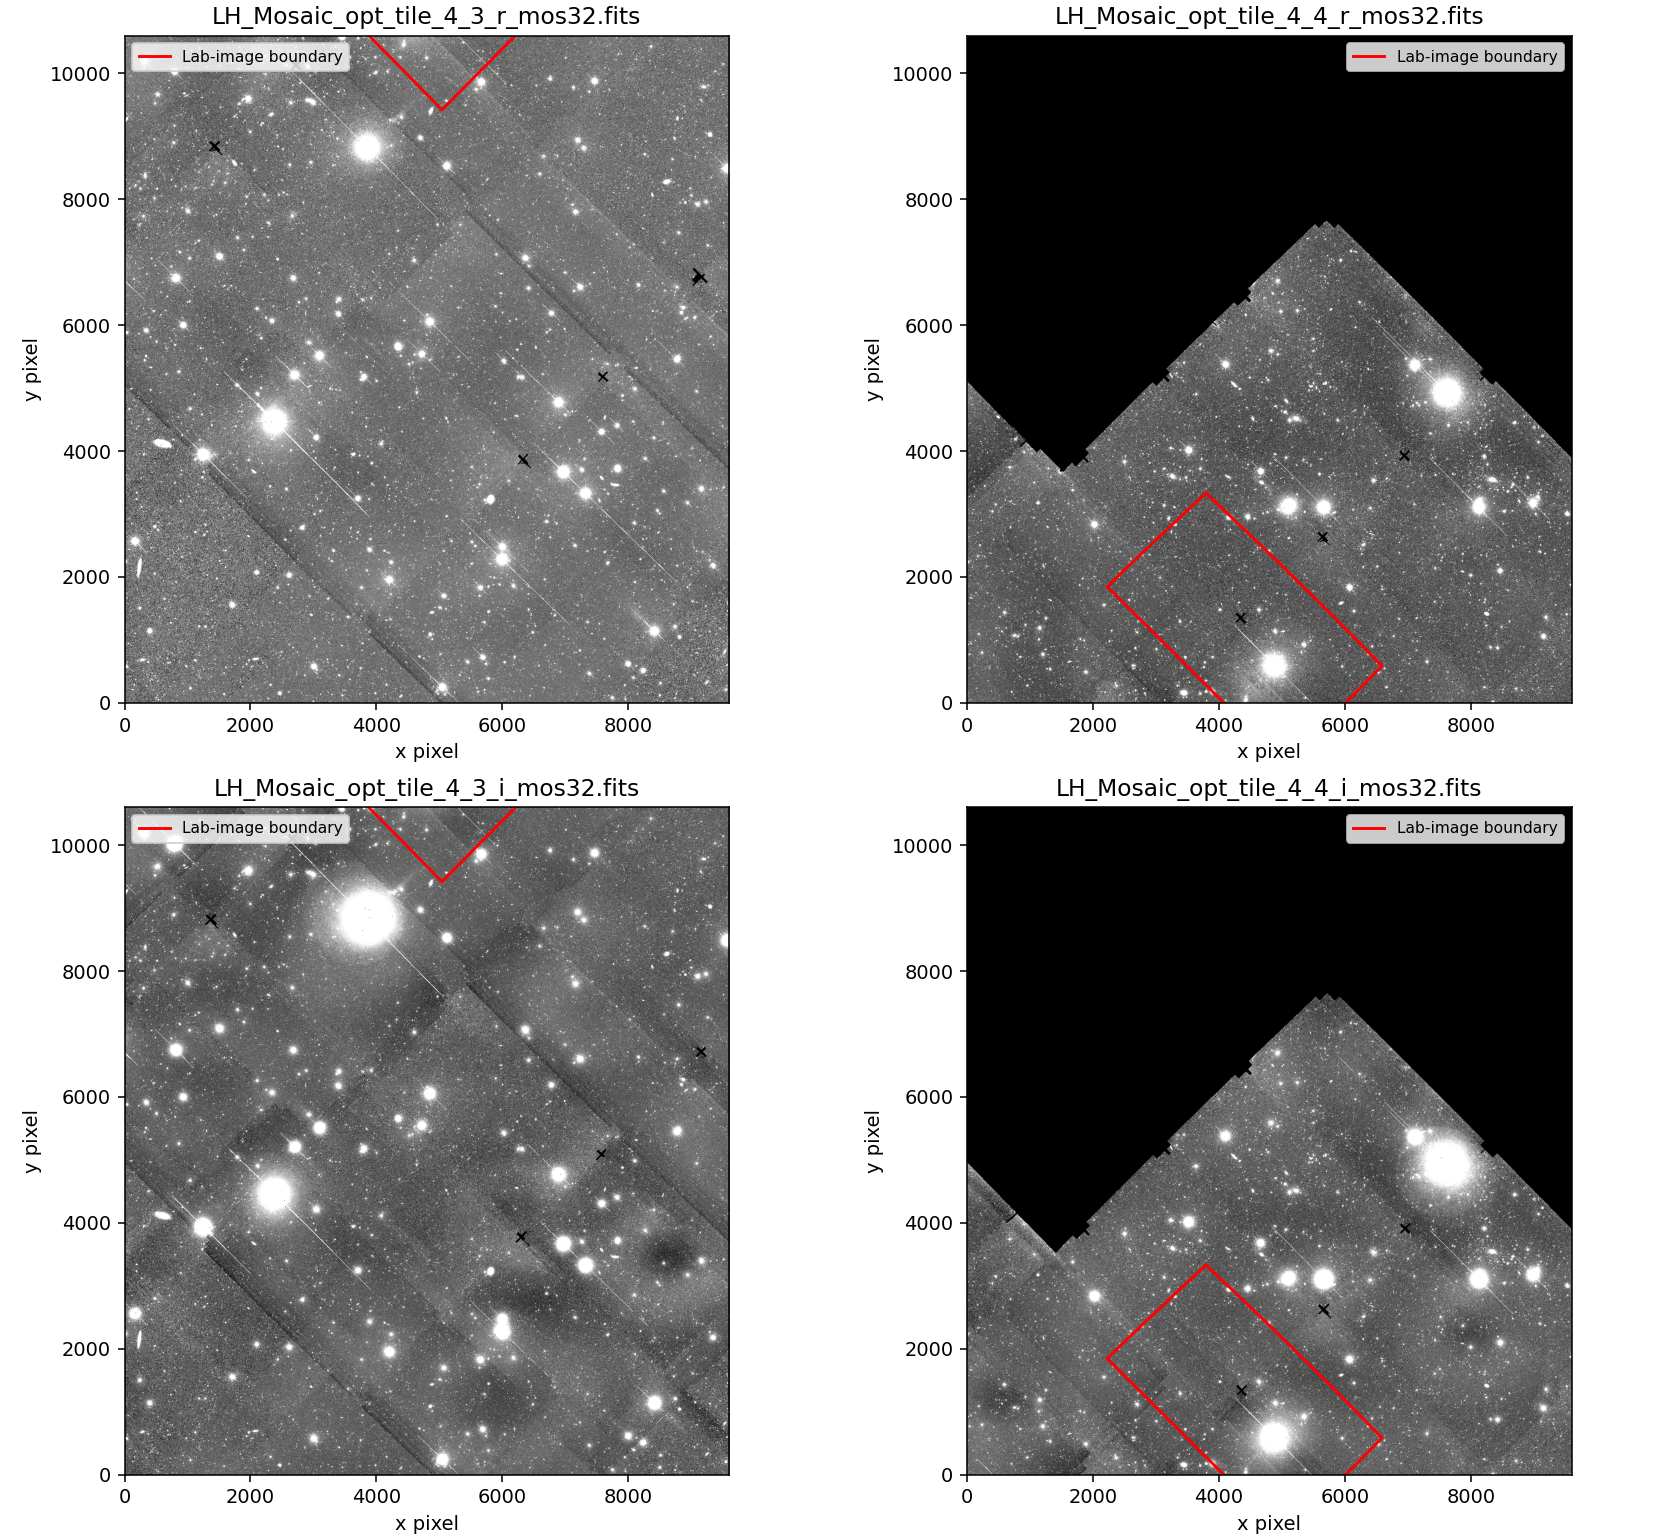

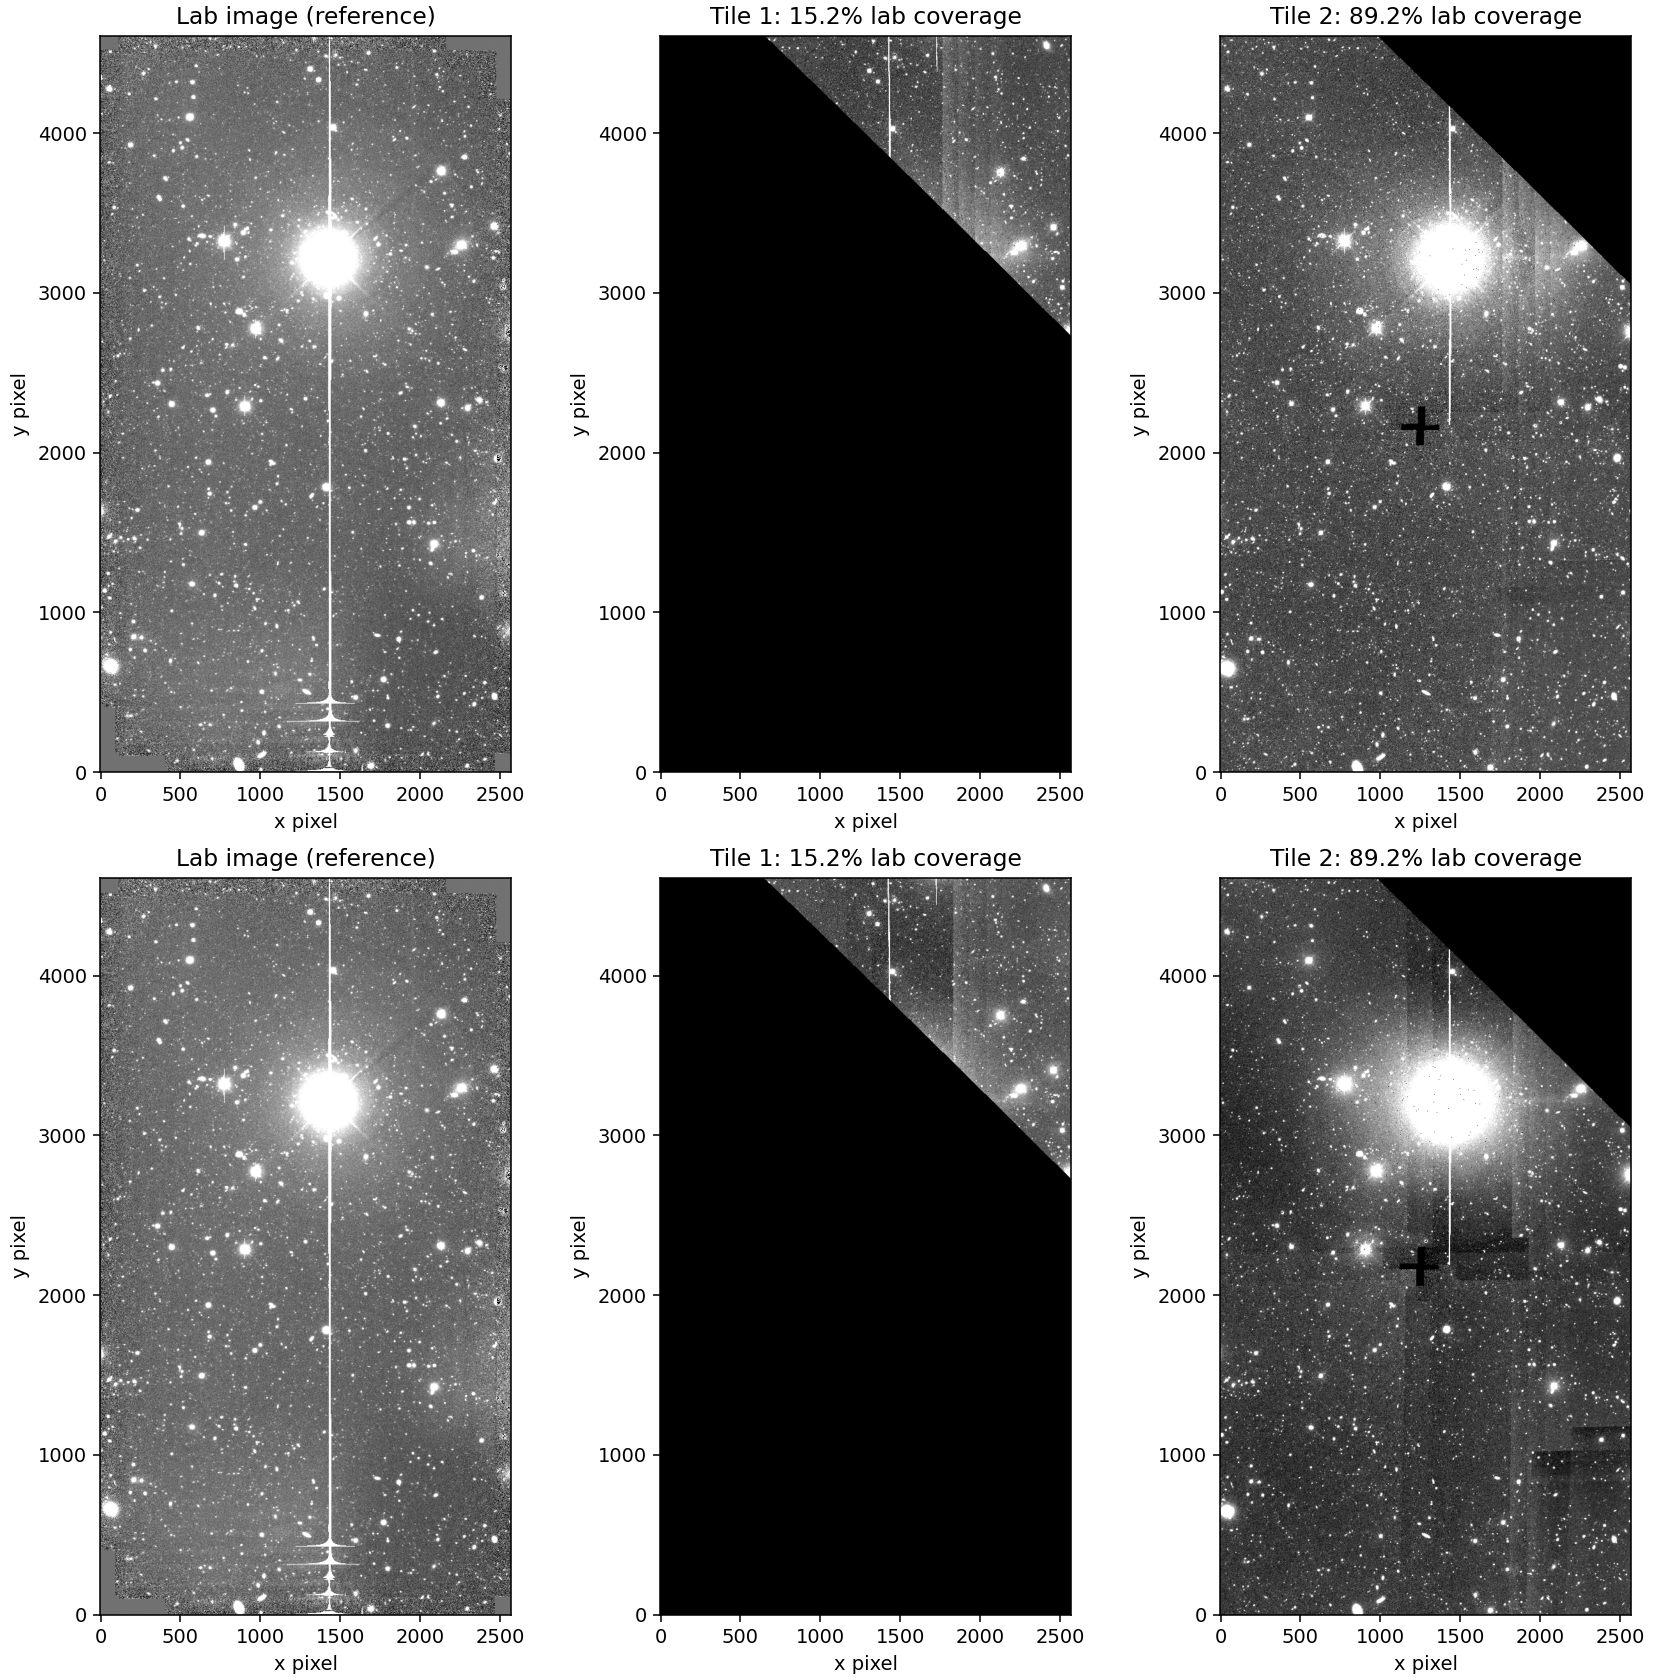

In [4]:
coverage = inspect_tiles(FILES, OUTPUT_FOLDER, show=False)
display(Image(filename=str(OUTPUT_FOLDER / "01_lab_footprint_on_archive_tiles.png")))
display(Image(filename=str(OUTPUT_FOLDER / "02_same_patch_in_each_tile.png")))

In [5]:
def measure_registration(lab,out):
    result=[]
    for group in ['original_band_tiles','second_band_tiles']:
     for tile in [1,2]:
      image=fits.getdata(out/f'{group}_tile{tile}_aligned.fits').astype(float)
      offsets=[];strength=[];positions=[]
      for y in range(300,lab.shape[0]-150,350):
       for x in range(200,lab.shape[1]-150,300):
        if abs(x-1435)<180 or np.hypot(x-1427,y-3220)<600: continue
        sl=np.s_[y-128:y+128,x-128:x+128]
        a=lab[sl].copy();b=image[sl].copy()
        valid=np.isfinite(b)&(a>0)&np.isfinite(a)
        if valid.mean()<.99: continue
        features=[]
        for v in [a,b]:
         v[~valid]=np.median(v[valid])
         v-=gaussian_filter(v,12)
         scale=np.median(np.abs(v[valid]-np.median(v[valid])))*1.4826
         v=np.arcsinh(np.clip(v/max(scale,1e-9),-5,100))
         v-=v.mean();features.append(v)
        a,b=features
        corr=fftconvolve(a,b[::-1,::-1],mode='same')
        center=np.array(corr.shape)//2
        small=corr[center[0]-25:center[0]+26,center[1]-25:center[1]+26]
        py,px=np.unravel_index(np.argmax(small),small.shape)
        if py in [0,50] or px in [0,50]:continue
        score=float(small[py,px]/np.sqrt(np.sum(a*a)*np.sum(b*b)))
        if score<.3:continue
        def delta(v0,v1,v2):
         denom=v0-2*v1+v2
         return .5*(v0-v2)/denom if denom else 0
        dx=px-25+delta(small[py,px-1],small[py,px],small[py,px+1])
        dy=py-25+delta(small[py-1,px],small[py,px],small[py+1,px])
        offsets.append([dx,dy]);strength.append(score);positions.append([x,y])
      stats={'group':group,'tile':tile,'patches':len(offsets),
             'shift_to_apply_to_archive_xy_pixels':np.median(offsets,axis=0).tolist() if offsets else None,
             'shift_spread_xy_pixels':np.std(offsets,axis=0).tolist() if offsets else None,
             'median_correlation_at_best_shift':float(np.median(strength)) if strength else None,
             'patch_centers_xy':positions,'patch_shifts_xy':offsets,'patch_correlations':strength}
      result.append(stats);print(group, 'tile', tile, ':', len(offsets), 'usable registration patches', flush=True)
    p=out/'analysis_report.json';r=json.loads(p.read_text());r['registration_checks']=result
    r['registration_interpretation']='Same field, but the initial header-based projection has a systematic positional offset. Refine astrometry before matched small-aperture colour photometry. Shifts are diagnostic only, not yet applied to FITS products.'
    r.pop('r_band_image_match_tests',None)
    p.write_text(json.dumps(r,indent=2))

    return result


In [6]:
lab_hdus, lab_index, lab_header, lab_wcs = open_image(LAB_FILE)
try:
    lab_image = np.asarray(lab_hdus[lab_index].section[:, :], dtype=float)
finally:
    lab_hdus.close()
(OUTPUT_FOLDER / "analysis_report.json").write_text(json.dumps(coverage, indent=2))
registration_checks = measure_registration(lab_image, OUTPUT_FOLDER)
for result in registration_checks:
    print(result["group"], "tile", result["tile"], "patches:", result["patches"])

the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]


original_band_tiles tile 1 : 4 usable registration patches
original_band_tiles tile 2 : 50 usable registration patches
second_band_tiles tile 1 : 4 usable registration patches
second_band_tiles tile 2 : 48 usable registration patches
original_band_tiles tile 1 patches: 4
original_band_tiles tile 2 patches: 50
second_band_tiles tile 1 patches: 4
second_band_tiles tile 2 patches: 48


In [7]:
def refine_registration(lab,header,out):
    report=json.loads((out/'analysis_report.json').read_text())
    shape=lab.shape
    def design(points,degree):
     x=(points[:,0]-shape[1]/2)/(shape[1]/2);y=(points[:,1]-shape[0]/2)/(shape[0]/2)
     return np.column_stack([x**a*y**(total-a) for total in range(degree+1) for a in range(total+1)])
    def fit(x,y,degree):
     A=design(x,degree);keep=np.ones(len(x),bool)
     for _ in range(5):
      coef=np.linalg.lstsq(A[keep],y[keep],rcond=None)[0]
      residual=np.linalg.norm(y-A@coef,axis=1)
      center=np.median(residual[keep]);spread=1.4826*np.median(np.abs(residual[keep]-center))
      new=residual<max(1.,center+3*spread)
      if new.sum()<A.shape[1]+3:break
      keep=new
     return coef,keep
    models=[]
    fig,axes=plt.subplots(2,2,figsize=(11,9),constrained_layout=True)
    corrected={}
    for row,group in enumerate(['original_band_tiles','second_band_tiles']):
     rows=[r for r in report['registration_checks'] if r['group']==group]
     positions=np.concatenate([r['patch_centers_xy'] for r in rows]); shifts=np.concatenate([r['patch_shifts_xy'] for r in rows])
     permutation=np.random.default_rng(42).permutation(len(positions));fold=np.empty(len(positions),int);fold[permutation]=np.arange(len(positions))%5
     trials=[]
     for degree in [1,2,3]:
      residual=[]
      for k in range(5):
       keep=fold!=k;coef,_=fit(positions[keep],shifts[keep],degree)
       residual.extend(np.linalg.norm(shifts[~keep]-design(positions[~keep],degree)@coef,axis=1))
      trials.append({'degree':degree,'held_out_median_offset_px':float(np.median(residual)),
                     'held_out_90_percent_offset_px':float(np.percentile(residual,90))})
     best=min(trials,key=lambda r:r['held_out_median_offset_px'])
     degree=best['degree'];coef,keep=fit(positions,shifts,degree)
     prediction=design(positions,degree)@coef
     residual=np.linalg.norm(shifts-prediction,axis=1)
     models.append({'group':group,'trials':trials,'chosen_degree':degree,'coefficients':coef.tolist(),
                    'patches_used':int(keep.sum()),'total_patches':len(positions),
                    'note':'Cross-validation of patch-correlation shifts, not independent catalogue astrometry.'})
     axes[row,0].quiver(positions[:,0],positions[:,1],shifts[:,0],shifts[:,1],angles='xy',scale_units='xy',scale=.15)
     axes[row,0].set(xlim=(0,shape[1]),ylim=(0,shape[0]),xlabel='x pixel',ylabel='y pixel',title=group+': measured offset vectors')
     axes[row,1].hist(residual,bins=20);axes[row,1].set(xlabel='Residual offset after fit (pixels)',ylabel='Patches',title=f'Degree {degree}; held-out median {best["held_out_median_offset_px"]:.2f}px')
     print(group,trials,flush=True)
     if best['held_out_median_offset_px']>=1:
      print('Registration not sufficiently reliable; no corrected mosaic produced.',flush=True);continue
     pieces=[]
     for tile in [1,2]:
      image=fits.getdata(out/f'{group}_tile{tile}_aligned.fits')
      result=np.full(shape,np.nan,np.float32)
      valid=np.isfinite(image)
      clean_image=np.where(valid,image,0)
      weights=valid.astype(np.float32)
      for start in range(0,shape[0],128):
       stop=min(start+128,shape[0]);yy,xx=np.mgrid[start:stop,:shape[1]]
       delta=(design(np.column_stack([xx.ravel(),yy.ravel()]),degree)@coef).reshape(*xx.shape,2)
       # Evaluate original projected tile at inverse displacement, approximately.
       # Refine inverse displacement once for the slowly varying fitted field.
       sx=xx-delta[...,0];sy=yy-delta[...,1]
       d2=(design(np.column_stack([sx.ravel(),sy.ravel()]),degree)@coef).reshape(*xx.shape,2)
       sx=xx-d2[...,0];sy=yy-d2[...,1]
       values=map_coordinates(clean_image,[sy,sx],order=1,mode='constant',cval=0,prefilter=False)
       weight=map_coordinates(weights,[sy,sx],order=1,mode='constant',cval=0,prefilter=False)
       use=weight>.999999;block=result[start:stop];block[use]=values[use]/weight[use]
      pieces.append(result)
      h=WCS(header).celestial.to_header(relax=True);h['HISTORY']='Visual-only interpolation with empirical geometric correction; no photometric calibration.'
      h['FILTER']='r' if group=='original_band_tiles' else 'i'
      h['PHOTCAL']=False
      fits.writeto(out/f'{group}_tile{tile}_registered_visual.fits',result,h,overwrite=True)
     combined=np.where(np.isfinite(pieces[0]),pieces[0],pieces[1])
     corrected[group]=combined
     fits.writeto(out/f'{group}_combined_visual.fits',combined,h,overwrite=True)
    fig.savefig(out/'04_registration_diagnostics.png',dpi=150);plt.close(fig)
    if len(corrected)==2:
     fig,axes=plt.subplots(1,3,figsize=(12,8),constrained_layout=True)
     for ax,img,title in zip(axes,[lab,corrected['original_band_tiles'],corrected['second_band_tiles']],['Lab r-band','Archive r: corrected visual alignment','Archive i: corrected visual alignment']):preview(ax,img,title)
     fig.savefig(out/'05_lab_r_and_i_registered.png',dpi=150);plt.close(fig)
    report['empirical_registration_models']=models
    report['registration_interpretation']='Diagnostic polynomial correction with held-out patch checks. Registered FITS products are visual-only, not calibrated or flux-conserving photometric mosaics.'
    (out/'analysis_report.json').write_text(json.dumps(report,indent=2))

    return corrected,models


original_band_tiles [{'degree': 1, 'held_out_median_offset_px': 3.8014730969196258, 'held_out_90_percent_offset_px': 10.825096733563212}, {'degree': 2, 'held_out_median_offset_px': 1.2763252350373504, 'held_out_90_percent_offset_px': 2.826746727372992}, {'degree': 3, 'held_out_median_offset_px': 0.5532683600271757, 'held_out_90_percent_offset_px': 1.323727748000764}]


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]


second_band_tiles [{'degree': 1, 'held_out_median_offset_px': 4.350373962213597, 'held_out_90_percent_offset_px': 11.865106462209974}, {'degree': 2, 'held_out_median_offset_px': 1.1581453271419861, 'held_out_90_percent_offset_px': 3.2319379637524146}, {'degree': 3, 'held_out_median_offset_px': 0.5142793911437249, 'held_out_90_percent_offset_px': 1.2571121565357417}]


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]
the PROJPn keyword is deprecated, use PVi_ma. [astropy.wcs.wcs]


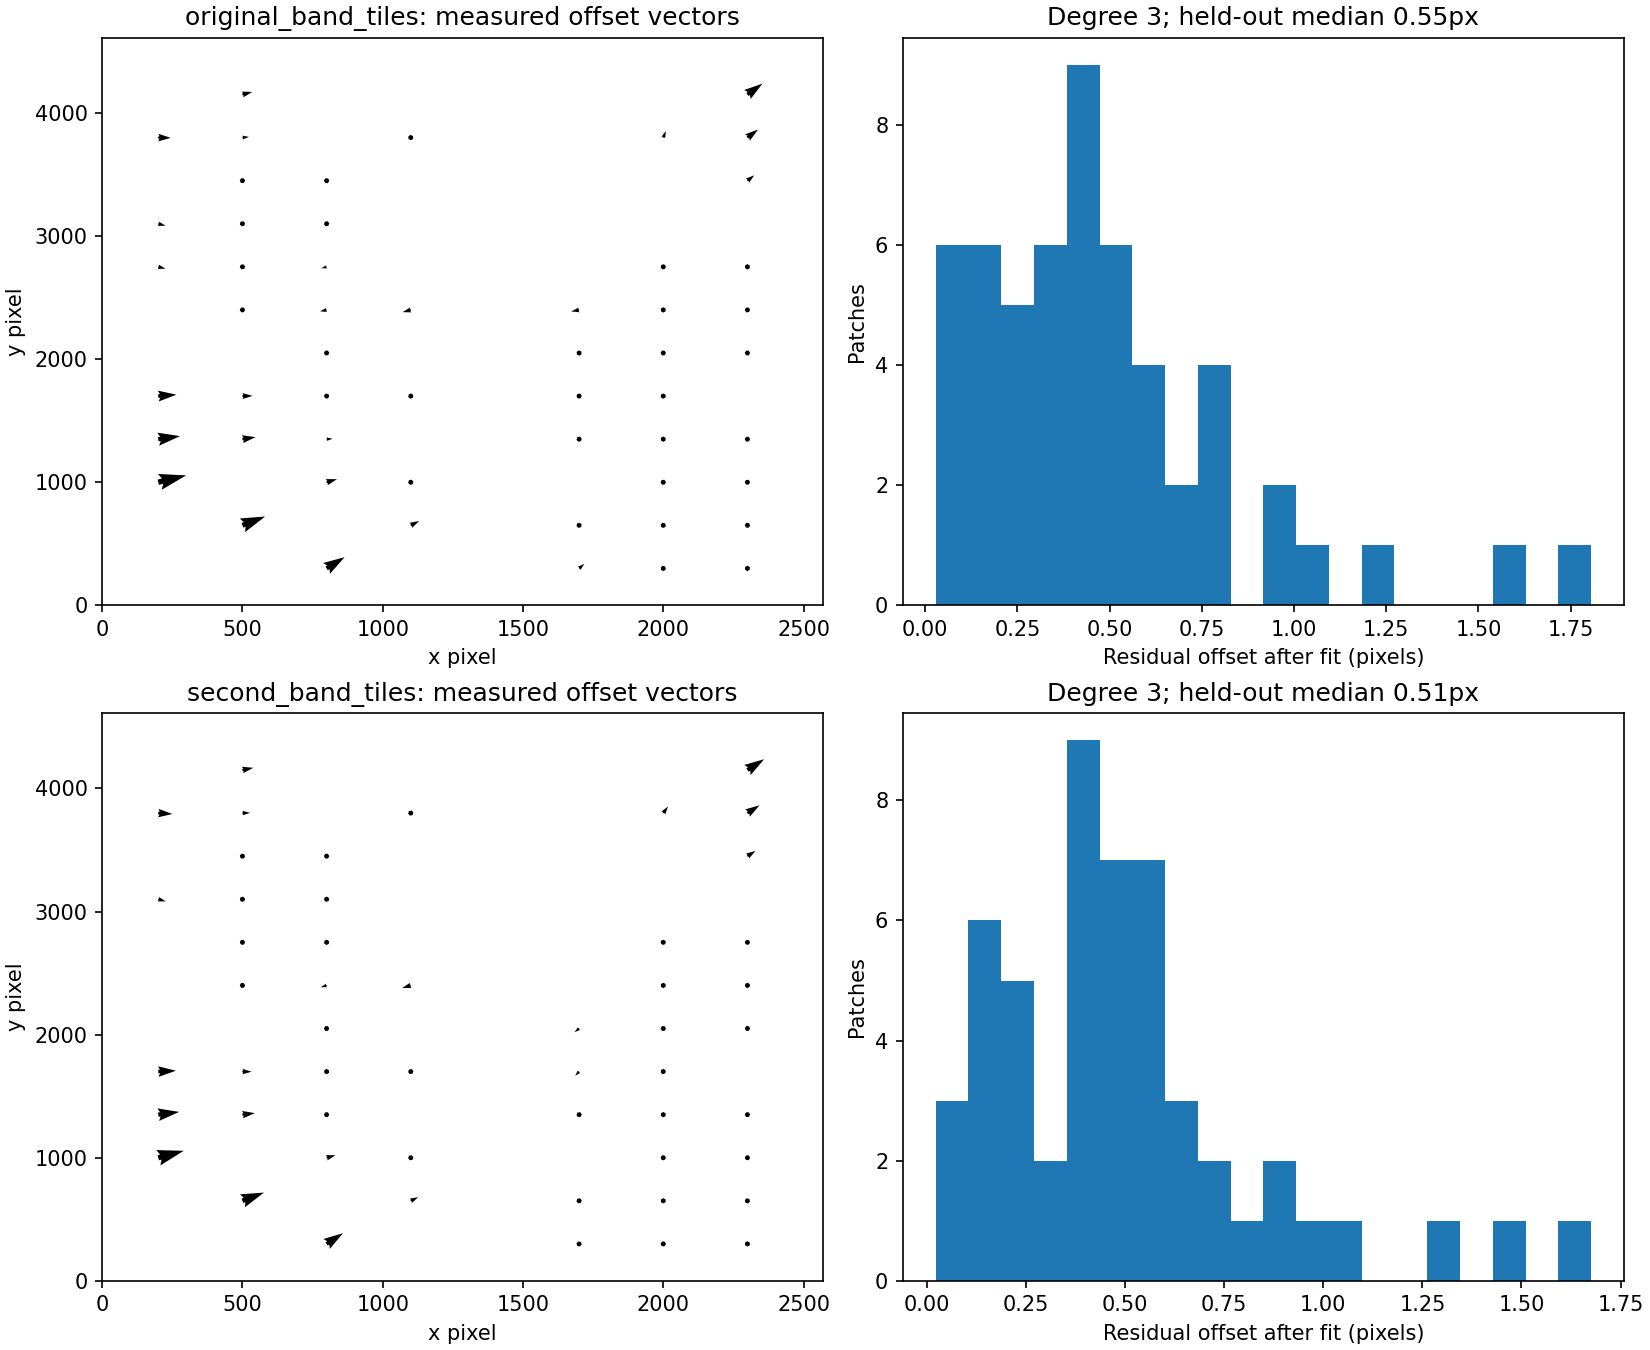

In [8]:
registered, registration_models = refine_registration(lab_image, lab_header, OUTPUT_FOLDER)
display(Image(filename=str(OUTPUT_FOLDER / "04_registration_diagnostics.png")))
if "second_band_tiles" not in registered:
    raise RuntimeError("i-band registration did not pass: inspect the diagnostics before proceeding.")

In [9]:
image2 = registered["second_band_tiles"]
reference_r = registered.get("original_band_tiles")
if reference_r is None:
    raise RuntimeError("r-band control alignment did not pass.")
lab_valid = np.isfinite(lab_image) & (lab_image > 0)
common_valid = lab_valid & np.isfinite(reference_r) & np.isfinite(image2)

image2_header = lab_wcs.to_header(relax=True)
image2_header["FILTER"] = "i SDSS k1019"
image2_header["PHOTCAL"] = False
image2_header["SRC1"] = I_4_3.name
image2_header["SRC2"] = I_4_4.name
image2_header["HISTORY"] = "Visual-only bilinear alignment; no flux-conserving reprojection or photometric calibration."
fits.writeto(OUTPUT_FOLDER / "image2_i_visual.fits", image2, image2_header, overwrite=True)
fits.writeto(OUTPUT_FOLDER / "common_valid_pixels.fits", common_valid.astype(np.uint8),
             lab_wcs.to_header(relax=True), overwrite=True)
print("Image 2 shape:", image2.shape)
print("Usable lab pixels with registered r and i data:", f"{common_valid.sum()/lab_valid.sum():.2%}")
assert image2.shape == lab_image.shape
assert np.isfinite(image2[common_valid]).all()
report = json.loads((OUTPUT_FOLDER / "analysis_report.json").read_text())
report["registered_joint_coverage_fraction"] = float(common_valid.sum()/lab_valid.sum())
report["image2_file"] = "image2_i_visual.fits"
(OUTPUT_FOLDER / "analysis_report.json").write_text(json.dumps(report, indent=2))

Image 2 shape: (4611, 2570)
Usable lab pixels with registered r and i data: 98.03%


23690

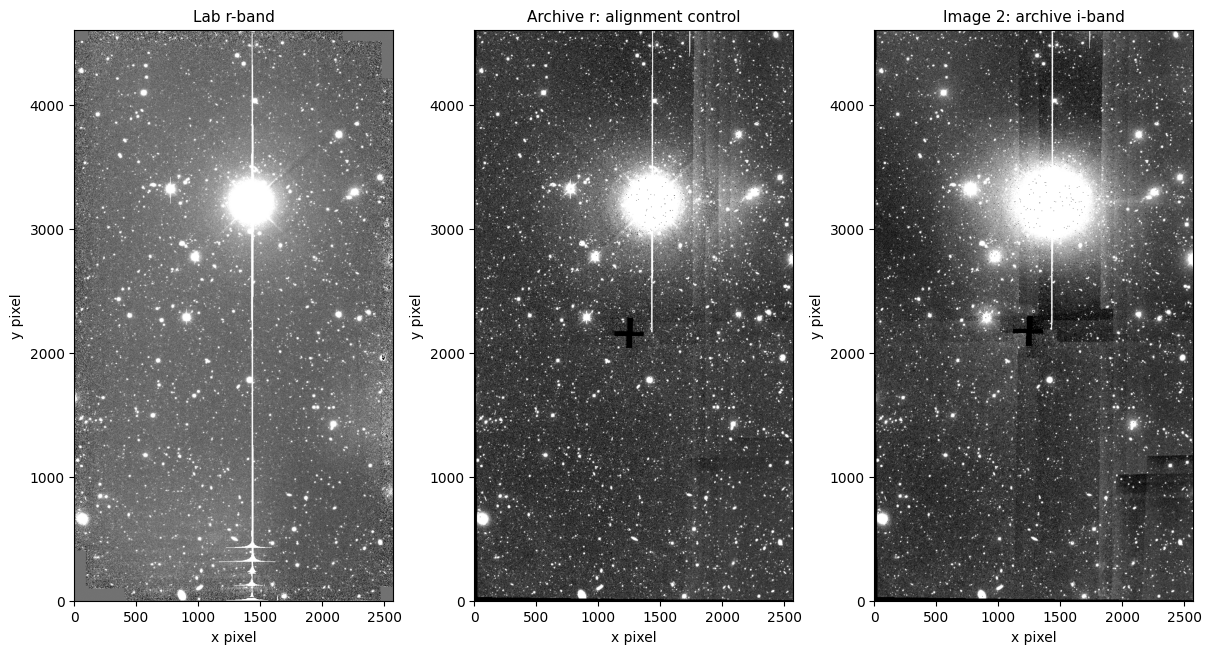

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 8), constrained_layout=True)
for ax, values, title in zip(axes, [lab_image, reference_r, image2],
                             ["Lab r-band", "Archive r: alignment control", "Image 2: archive i-band"]):
    preview(ax, values, title)
    ax.title.set_fontsize(11)
fig.savefig(OUTPUT_FOLDER / "final_lab_r_and_image2_i.png", dpi=150)
plt.show()